<a href="https://colab.research.google.com/github/marcelosantosjunior2027/IFOOD_GENAI_PORTIF-LIO/blob/main/Economia_%26_Finan%C3%A7as_Simula%C3%A7%C3%A3o_Estoc%C3%A1stica_de_Viabilidade.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

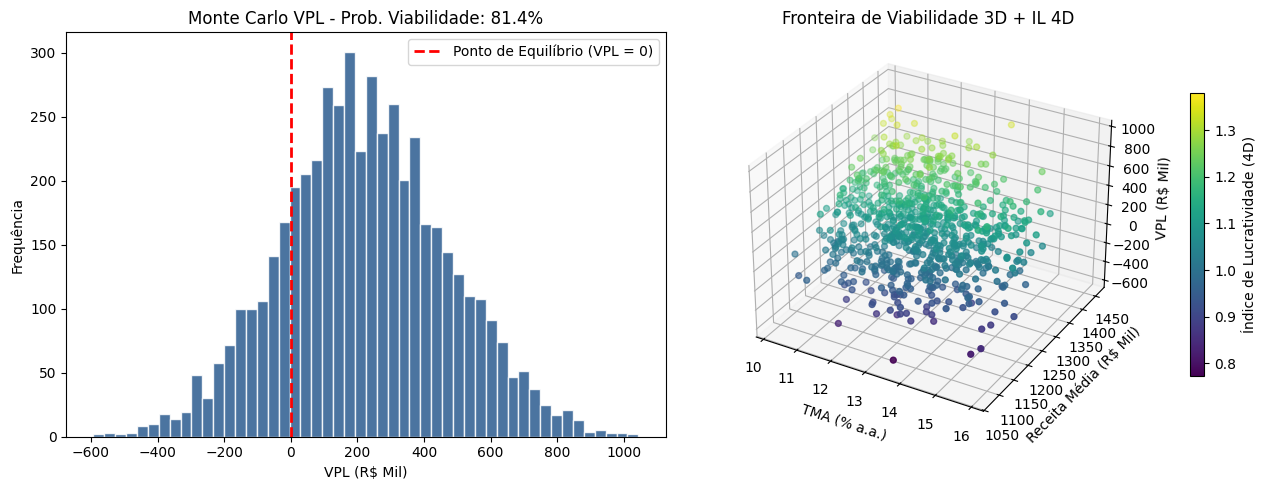

In [1]:
# AUTOR: MARCELO DE OLIVEIRA SANTOS JUNIOR
# SIMULAÇÃO PARA ANÁLISE DE VIABILIDADE ECONÔMICA

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(101)
n_sim = 5000
capex = 2_500_000.0

# Premissas estocásticas realistas (5 anos)
tma = rng.triangular(0.10, 0.125, 0.16, n_sim)
annual_rev = rng.normal(1_250_000.0, 140_000.0, (n_sim, 5))
annual_opex = rng.normal(480_000.0, 45_000.0, (n_sim, 5))
net_cf = annual_rev - annual_opex

years = np.arange(1, 6)
discount_factors = 1.0 / np.power(1.0 + tma[:, None], years[None, :])
vpl = -capex + np.sum(net_cf * discount_factors, axis=1)
prob_success = np.mean(vpl > 0) * 100

fig = plt.figure(figsize=(13, 5))

# 2D: Distribuição de Probabilidade do VPL
ax1 = fig.add_subplot(1, 2, 1)
ax1.hist(vpl / 1e3, bins=50, color="#2b5c8f", edgecolor="white", alpha=0.85)
ax1.axvline(0, color="red", lw=2, linestyle="--", label="Ponto de Equilíbrio (VPL = 0)")
ax1.set_title(f"Monte Carlo VPL - Prob. Viabilidade: {prob_success:.1f}%")
ax1.set_xlabel("VPL (R$ Mil)")
ax1.set_ylabel("Frequência")
ax1.legend()

# 3D/4D: Espaço de Risco (TMA x Receita x VPL x Índice de Lucratividade)
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
il = (vpl + capex) / capex  # 4ª dimensão: Índice de Lucratividade
sc = ax2.scatter(tma[:800] * 100, annual_rev[:800].mean(axis=1) / 1e3, vpl[:800] / 1e3, c=il[:800], cmap="viridis", s=18)
cbar = plt.colorbar(sc, ax=ax2, pad=0.1, shrink=0.7)
cbar.set_label("Índice de Lucratividade (4D)")
ax2.set_title("Fronteira de Viabilidade 3D + IL 4D")
ax2.set_xlabel("TMA (% a.a.)")
ax2.set_ylabel("Receita Média (R$ Mil)")
ax2.set_zlabel("VPL (R$ Mil)")

plt.tight_layout()
plt.show()